# Online Retail: RFM Customer Segmentation with K-Means (K = 5)

**Goal:** understand how customers buy, then group them into 5 actionable segments and attach a marketing action to each one.

**Dataset:** *Online Retail.xlsx* - every transaction of a UK-based online gift retailer between 01-Dec-2010 and 09-Dec-2011 (541,909 rows, 8 columns).

**Notebook map**

| # | Section | What it answers |
|---|---------|-----------------|
| 1 | Setup & data loading | What does the raw data look like? |
| 2 | Data quality checks | Missing values, duplicates, bad values |
| 3 | Cleaning for customer analysis | Which rows can be used? |
| 4 | Exploratory analysis | Products, customers, time, countries |
| 5 | Returns analysis | What is being returned, and by whom? |
| 6 | Customer behaviour & business KPIs | Bulk buyers, AOV, Pareto, dead stock |
| 7 | RFM analysis | Recency, Frequency, Monetary + 1-5 scores |
| 8 | K-Means clustering (K = 5) | 5 data-driven customer groups |
| 9 | Business Translation Matrix | Cluster number -> marketing strategy |
| 10 | Recommendations & conclusion | What should the business do? |

**What was fixed in this version** (everything else is unchanged)

1. **Heat-map error** (`Length mismatch: 6 vs 7`) - the data has no Saturday transactions, so the pivot has 6 weekday columns, not 7.
2. **Returns = 0** - returns were searched inside `rfm_df`, which had already dropped every row with `Quantity <= 0`. They are now taken from the original `df` (cancelled invoices).
3. **Downstream `IndexError` charts** - the two returns bar charts failed only because the returns table was empty; fixed by (2).
4. **Frequency score had only 4 levels** (so `F = 5` could never exist and *Champions* were impossible). Ties are now broken with `rank(method='first')`.
5. **K-Means now uses K = 5**, and the Business Translation Matrix was rebuilt for 5 clusters.

---
## 1. Setup & data loading
Import the libraries and load the raw Excel file. `df` is kept as the **untouched original**; every analysis works on a copy.

In [1]:
# Libraries: pandas/numpy for data, matplotlib/seaborn for charts
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 

In [2]:
# Load the raw data and preview the first rows
df=pd.read_excel("Online Retail.xlsx")
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


---
## 2. Data quality checks
Column types, size, duplicated rows and missing values.
Key facts: **~25 % of rows have no `CustomerID`** (they cannot be used for customer segmentation), and there are **5,268 duplicated rows**.

In [3]:
# Column types and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [4]:
# Number of rows and columns
df.shape

(541909, 8)

In [5]:
# Fully duplicated rows
df.duplicated().sum()

np.int64(5268)

In [6]:
# Missing values per column (CustomerID and Description)
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [7]:
# Convert InvoiceDate to datetime and extract calendar features
# Convert InvoiceDate to datetime
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

# Extract date/time features
df['Year'] = df['InvoiceDate'].dt.year
df['Month'] = df['InvoiceDate'].dt.month
df['DayOfWeek'] = df['InvoiceDate'].dt.dayofweek
df['Hour'] = df['InvoiceDate'].dt.hour

In [8]:
# Summary statistics (note the negative Quantity / UnitPrice values = returns & adjustments)
df.describe().T

,count,mean,min,25%,50%,75%,max,std
Quantity,541909.0,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,2011-07-04 13:34:57.156386048,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303
Year,541909.0,2010.921609,2010.0,2011.0,2011.0,2011.0,2011.0,0.268787
Month,541909.0,7.553128,1.0,5.0,8.0,11.0,12.0,3.509055
DayOfWeek,541909.0,2.431277,0.0,1.0,2.0,4.0,6.0,1.844709
Hour,541909.0,13.078729,6.0,11.0,13.0,15.0,20.0,2.44327


---
## 3. Cleaning for customer analysis
`rfm_df` keeps only **genuine purchases by identifiable customers**:
no missing `CustomerID`, `Quantity > 0` and `UnitPrice > 0`. `Revenue = Quantity x UnitPrice`.

> Because returns have negative quantities, they are **not** in `rfm_df`. Returns are analysed separately in Section 5.

In [9]:
# Build rfm_df: valid purchases with a known customer + Revenue column
# Keep original data
rfm_df = df.copy()

# 1. Remove transactions that cannot be assigned to a customer
rfm_df = rfm_df.dropna(subset=['CustomerID'])

# 2. Keep genuine positive-quantity transactions
rfm_df = rfm_df[rfm_df['Quantity'] > 0]

# 3. Keep positive prices
rfm_df = rfm_df[rfm_df['UnitPrice'] > 0]

# 4. Calculate revenue
rfm_df['Revenue'] = (
    rfm_df['Quantity'] * rfm_df['UnitPrice']
)

# Check result
print(rfm_df.shape)
print(rfm_df.head())

(397884, 13)
  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  Year  Month  \
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom  2010     12   
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  2010     12   
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom  2010     12   
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  2010     12   
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  2010     12   

   DayOfWeek  Hour  Revenue  
0          2     8    15.30  
1          2     8    20.34  
2

### Skewness and outliers
Revenue, Quantity and UnitPrice are extremely right-skewed with many outliers (a few wholesale orders are huge).
This is why the RFM features are **log-transformed** before K-Means in Section 8.

Numeric columns:
['Quantity', 'UnitPrice', 'CustomerID', 'Year', 'Month', 'DayOfWeek', 'Hour', 'Revenue']

Skewness:
Revenue       451.443182
Quantity      409.892972
UnitPrice     204.032727
DayOfWeek       0.396272
Hour            0.189029
CustomerID      0.025729
Month          -0.444803
Year           -3.504545
dtype: float64

Skewness Summary:
              Skewness             Distribution
Revenue     451.443182             Right-skewed
Quantity    409.892972             Right-skewed
UnitPrice   204.032727             Right-skewed
DayOfWeek     0.396272  Approximately symmetric
Hour          0.189029  Approximately symmetric
CustomerID    0.025729  Approximately symmetric
Month        -0.444803  Approximately symmetric
Year         -3.504545              Left-skewed

Outlier Summary:
       Column        Q1        Q3      IQR  Lower Bound  Upper Bound  \
0    Quantity      2.00     12.00    10.00        -13.0        27.00   
1   UnitPrice      1.25      3.75     2.50         -2.5

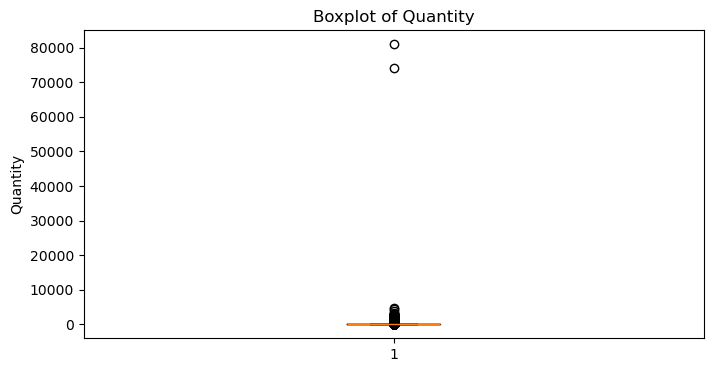

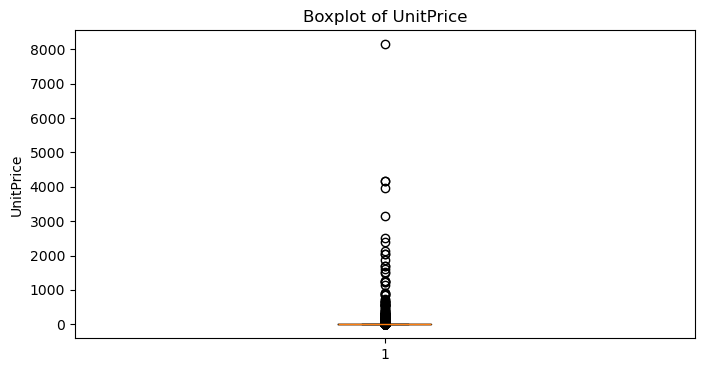

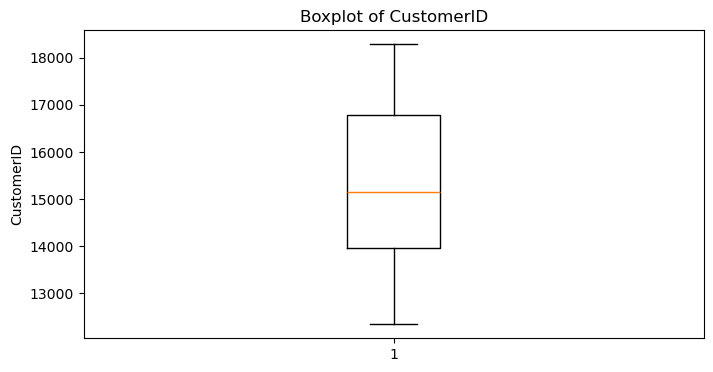

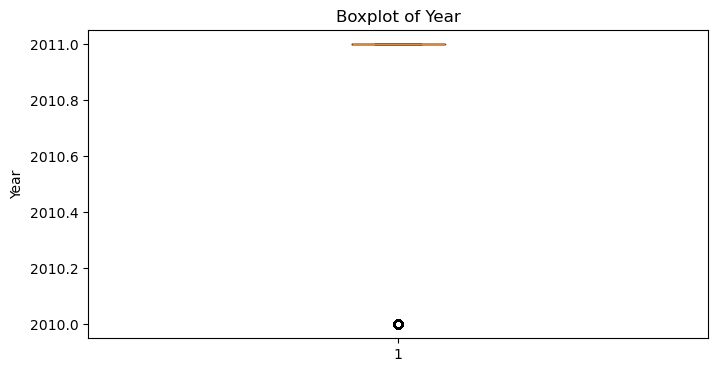

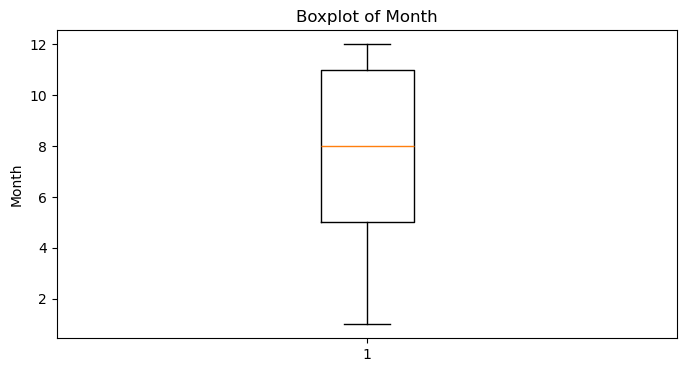

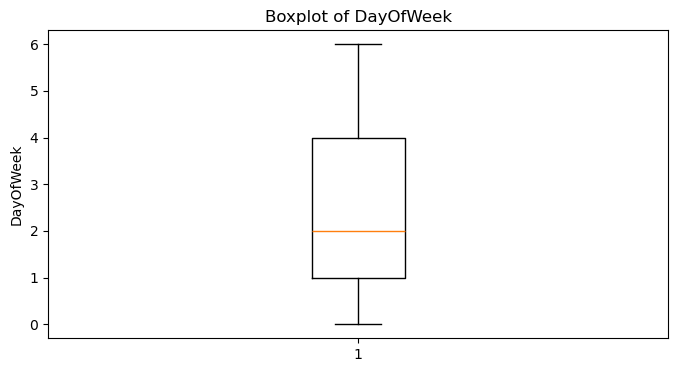

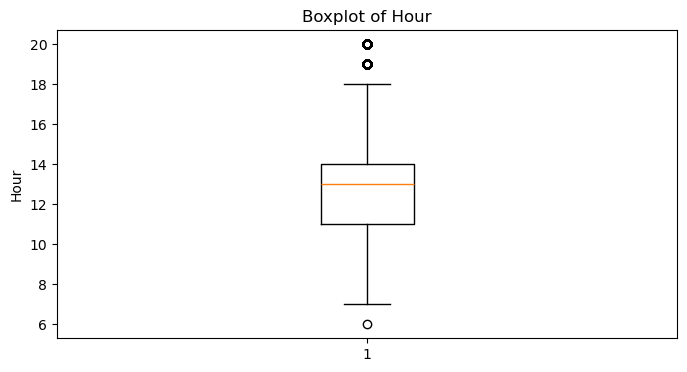

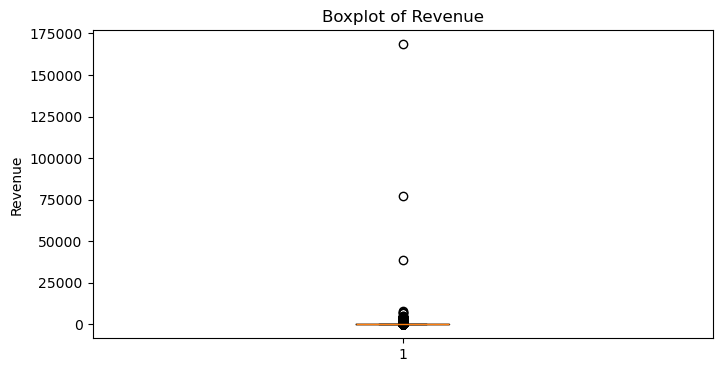

In [10]:
# Skewness + IQR outlier detection + boxplots for every numeric column
# ============================================================
# 1. Select numeric columns
# ============================================================

numeric_cols = rfm_df.select_dtypes(include=np.number).columns

print("Numeric columns:")
print(list(numeric_cols))


# ============================================================
# 2. Detect skewness
# ============================================================

skewness = rfm_df[numeric_cols].skew().sort_values(ascending=False)

print("\nSkewness:")
print(skewness)


# Classify skewness
def skewness_type(x):
    if abs(x) < 0.5:
        return "Approximately symmetric"
    elif x >= 0.5:
        return "Right-skewed"
    else:
        return "Left-skewed"


skewness_summary = pd.DataFrame({
    'Skewness': skewness,
    'Distribution': skewness.apply(skewness_type)
})

print("\nSkewness Summary:")
print(skewness_summary)


# ============================================================
# 3. Detect outliers using IQR
# ============================================================

outlier_summary = []

for col in numeric_cols:

    Q1 = rfm_df[col].quantile(0.25)
    Q3 = rfm_df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = rfm_df[
        (rfm_df[col] < lower_bound) |
        (rfm_df[col] > upper_bound)
    ]

    outlier_count = len(outliers)
    outlier_percentage = (outlier_count / len(rfm_df)) * 100

    outlier_summary.append({
        'Column': col,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'Outlier Count': outlier_count,
        'Outlier %': outlier_percentage
    })


outlier_summary = pd.DataFrame(outlier_summary)

print("\nOutlier Summary:")
print(outlier_summary)


# ============================================================
# 4. Boxplots for numeric columns
# ============================================================

for col in numeric_cols:

    plt.figure(figsize=(8, 4))
    plt.boxplot(rfm_df[col].dropna())
    plt.title(f'Boxplot of {col}')
    plt.ylabel(col)
    plt.show()

---
## 4. Exploratory analysis
### 4.1 Products
Best sellers by **units** and by **revenue**. Note that `POSTAGE` and `Manual` appear in the revenue ranking: they are service lines, not physical products.

Top 10 products by units sold:
Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        77916
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54415
JUMBO BAG RED RETROSPOT               46181
WHITE HANGING HEART T-LIGHT HOLDER    36725
ASSORTED COLOUR BIRD ORNAMENT         35362
PACK OF 72 RETROSPOT CAKE CASES       33693
POPCORN HOLDER                        30931
RABBIT NIGHT LIGHT                    27202
MINI PAINT SET VINTAGE                26076
Name: Quantity, dtype: int64


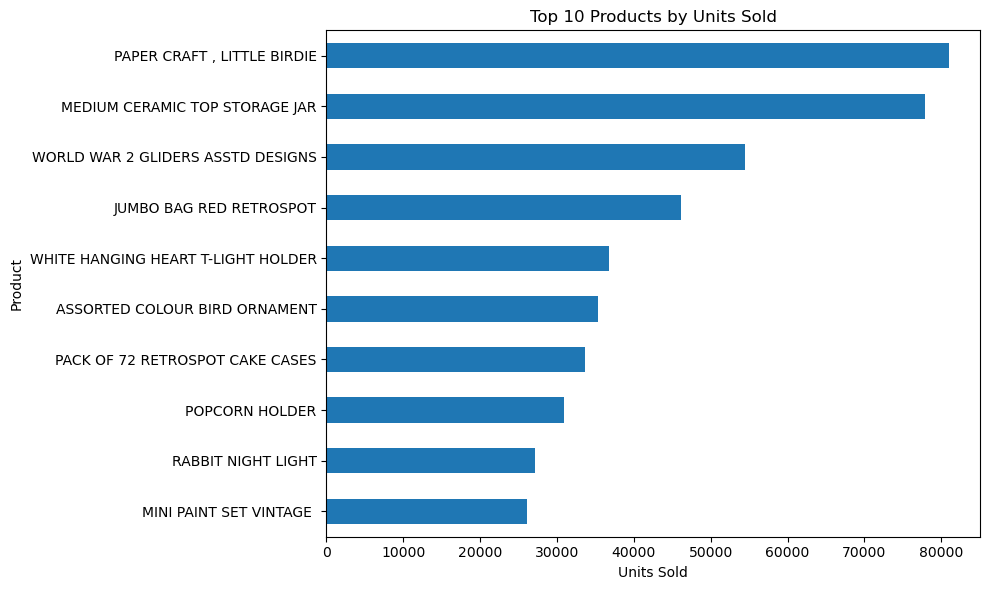

In [11]:
# Top 10 products by units sold
# Total units sold by product
product_units = (
    rfm_df.groupby('Description')['Quantity']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 products by units sold:")
print(product_units)

# Visualization
plt.figure(figsize=(10, 6))
product_units.sort_values().plot(kind='barh')

plt.title('Top 10 Products by Units Sold')
plt.xlabel('Units Sold')
plt.ylabel('Product')
plt.tight_layout()
plt.show()

Top 10 products by revenue:
Description
PAPER CRAFT , LITTLE BIRDIE           168469.60
REGENCY CAKESTAND 3 TIER              142592.95
WHITE HANGING HEART T-LIGHT HOLDER    100448.15
JUMBO BAG RED RETROSPOT                85220.78
MEDIUM CERAMIC TOP STORAGE JAR         81416.73
POSTAGE                                77803.96
PARTY BUNTING                          68844.33
ASSORTED COLOUR BIRD ORNAMENT          56580.34
Manual                                 53779.93
RABBIT NIGHT LIGHT                     51346.20
Name: Revenue, dtype: float64


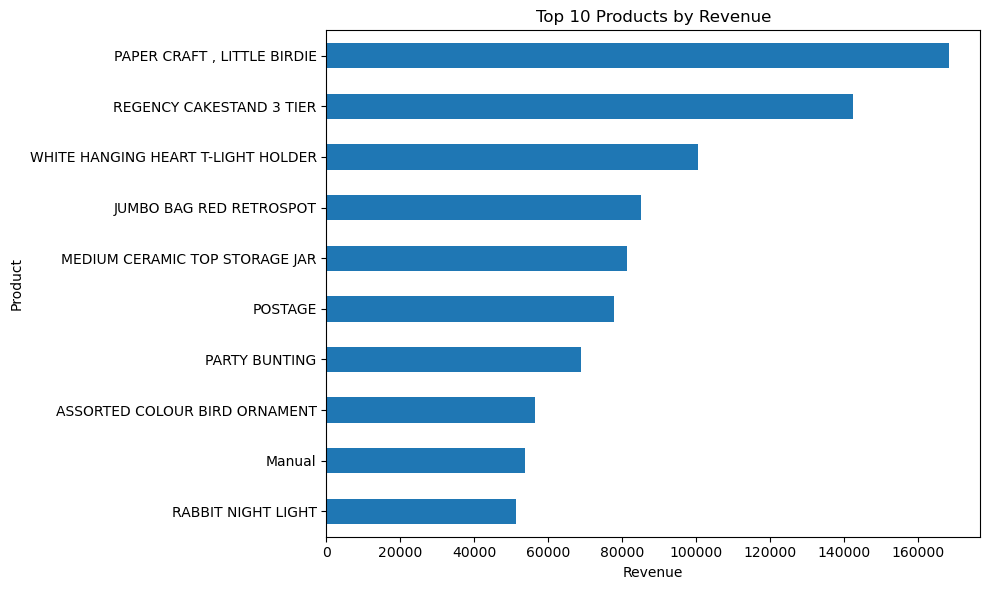

In [12]:
# Top 10 products by revenue
# Calculate revenue
rfm_df['Revenue'] = rfm_df['Quantity'] * rfm_df['UnitPrice']

product_revenue = (
    rfm_df.groupby('Description')['Revenue']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 products by revenue:")
print(product_revenue)

plt.figure(figsize=(10, 6))
product_revenue.sort_values().plot(kind='barh')

plt.title('Top 10 Products by Revenue')
plt.xlabel('Revenue')
plt.ylabel('Product')
plt.tight_layout()
plt.show()

### 4.2 Customers
A very small number of customers generate a large share of the revenue (wholesale-type buyers).

Top 10 customers by revenue:
CustomerID
14646.0    280206.02
18102.0    259657.30
17450.0    194550.79
16446.0    168472.50
14911.0    143825.06
12415.0    124914.53
14156.0    117379.63
17511.0     91062.38
16029.0     81024.84
12346.0     77183.60
Name: Revenue, dtype: float64


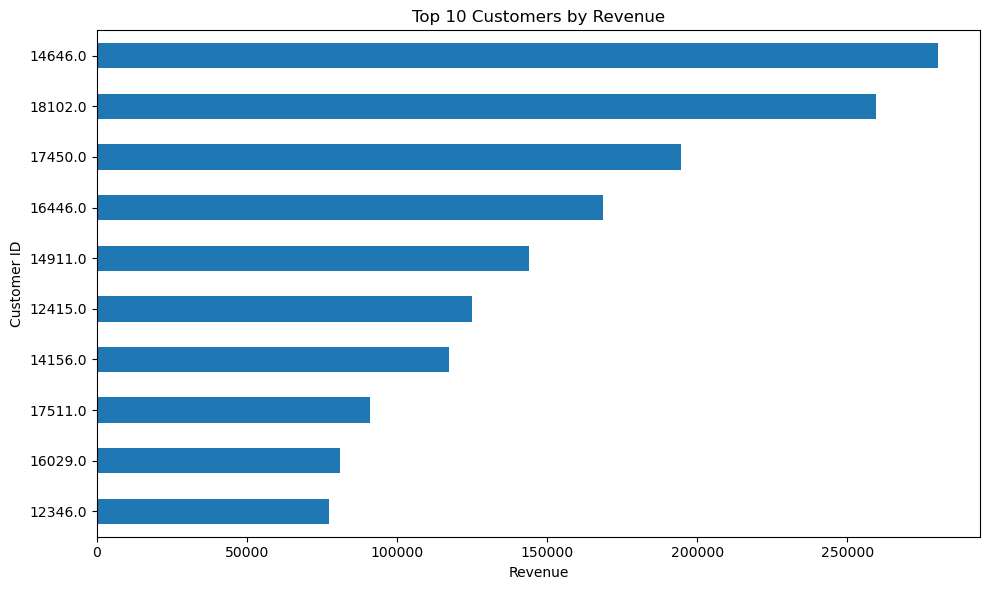

In [13]:
# Top 10 customers by revenue
# Customer revenue
customer_revenue = (
    rfm_df.groupby('CustomerID')['Revenue']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 customers by revenue:")
print(customer_revenue)

plt.figure(figsize=(10, 6))
customer_revenue.sort_values().plot(kind='barh')

plt.title('Top 10 Customers by Revenue')
plt.xlabel('Revenue')
plt.ylabel('Customer ID')
plt.tight_layout()
plt.show()

Top 10 customers by number of orders:
CustomerID
12748.0    209
14911.0    201
17841.0    124
13089.0     97
14606.0     93
15311.0     91
12971.0     86
14646.0     73
16029.0     63
13408.0     62
Name: InvoiceNo, dtype: int64


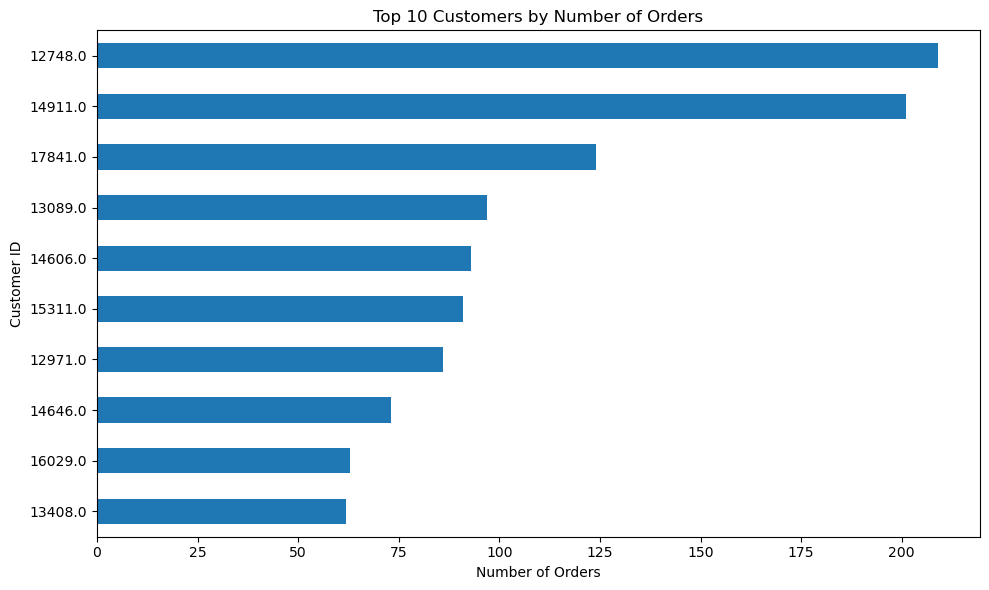

In [14]:
# Top 10 customers by number of orders
customer_orders = (
    rfm_df.groupby('CustomerID')['InvoiceNo']
    .nunique()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 customers by number of orders:")
print(customer_orders)

plt.figure(figsize=(10, 6))
customer_orders.sort_values().plot(kind='barh')

plt.title('Top 10 Customers by Number of Orders')
plt.xlabel('Number of Orders')
plt.ylabel('Customer ID')
plt.tight_layout()
plt.show()

### 4.3 Time patterns
Monthly trend, month-of-year, day-of-week and hour-of-day. Revenue rises sharply from **September to November**; **Thursday** is the strongest weekday, Sunday the weakest, and there are **no Saturday transactions**. December 2011 is incomplete (data ends 9-Dec).

InvoiceDate
2010-12-31     572713.890
2011-01-31     569445.040
2011-02-28     447137.350
2011-03-31     595500.760
2011-04-30     469200.361
2011-05-31     678594.560
2011-06-30     661213.690
2011-07-31     600091.011
2011-08-31     645343.900
2011-09-30     952838.382
2011-10-31    1039318.790
2011-11-30    1161817.380
2011-12-31     518192.790
Freq: ME, Name: Revenue, dtype: float64


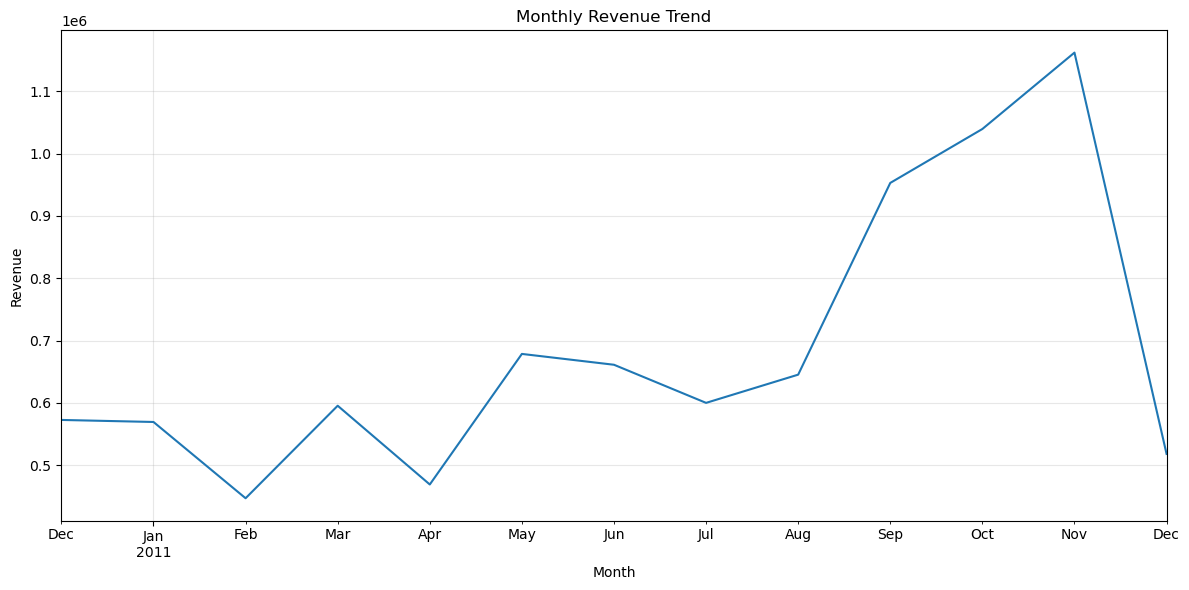

In [15]:
# Monthly revenue trend (Dec-2010 to Dec-2011)
monthly_revenue = (
    rfm_df
    .set_index('InvoiceDate')
    .resample('ME')['Revenue']
    .sum()
)

print(monthly_revenue)

plt.figure(figsize=(12, 6))
monthly_revenue.plot()

plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Revenue by month:
Month
1      569445.040
2      447137.350
3      595500.760
4      469200.361
5      678594.560
6      661213.690
7      600091.011
8      645343.900
9      952838.382
10    1039318.790
11    1161817.380
12    1090906.680
Name: Revenue, dtype: float64


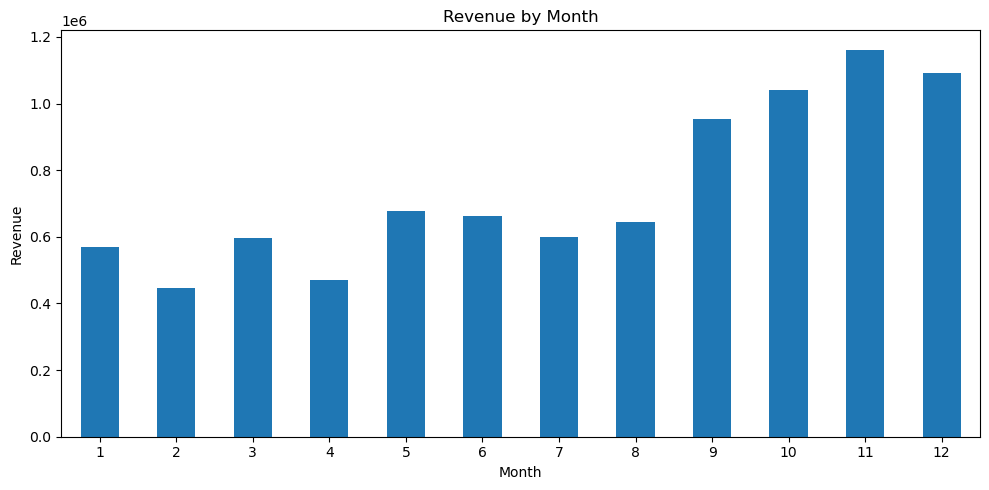

In [16]:
# Revenue by calendar month
rfm_df['Month'] = rfm_df['InvoiceDate'].dt.month

monthly_sales = (
    rfm_df.groupby('Month')['Revenue']
    .sum()
)

print("Revenue by month:")
print(monthly_sales)

plt.figure(figsize=(10, 5))
monthly_sales.plot(kind='bar')

plt.title('Revenue by Month')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Revenue by weekday:
Monday       1367146.411
Tuesday      1700634.631
Wednesday    1588336.170
Thursday     1976859.070
Friday       1485917.401
Sunday        792514.221
Name: Revenue, dtype: float64


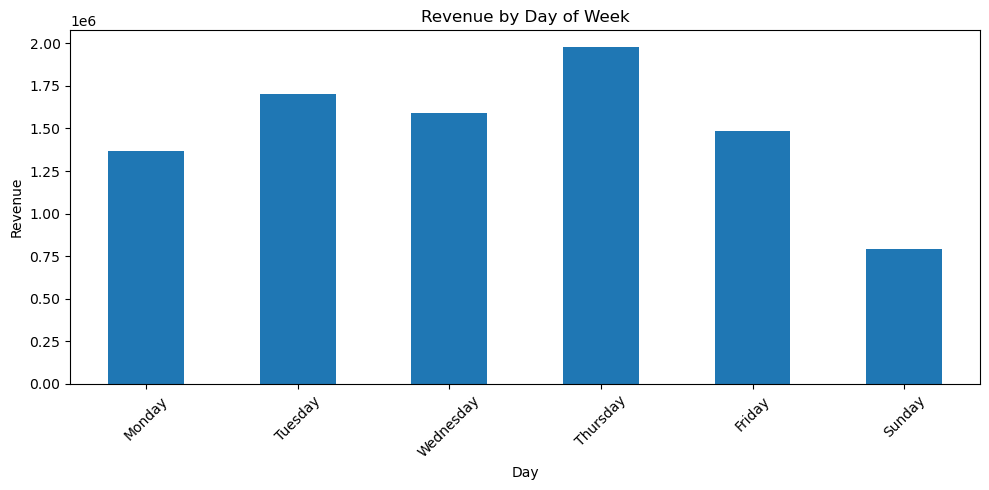

In [17]:
# Revenue by day of week
rfm_df['DayOfWeek'] = rfm_df['InvoiceDate'].dt.dayofweek

weekday_names = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

weekday_sales = (
    rfm_df.groupby('DayOfWeek')['Revenue']
    .sum()
)

weekday_sales.index = [
    weekday_names[i] for i in weekday_sales.index
]

print("Revenue by weekday:")
print(weekday_sales)

plt.figure(figsize=(10, 5))
weekday_sales.plot(kind='bar')

plt.title('Revenue by Day of Week')
plt.xlabel('Day')
plt.ylabel('Revenue')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Revenue by hour:
Hour
6           4.250
7       31059.210
8      282115.630
9      842605.171
10    1261192.571
11    1104558.750
12    1378571.480
13    1173264.750
14     995629.371
15     966191.750
16     468885.800
17     234413.521
18     104954.430
19      49028.460
20      18932.760
Name: Revenue, dtype: float64


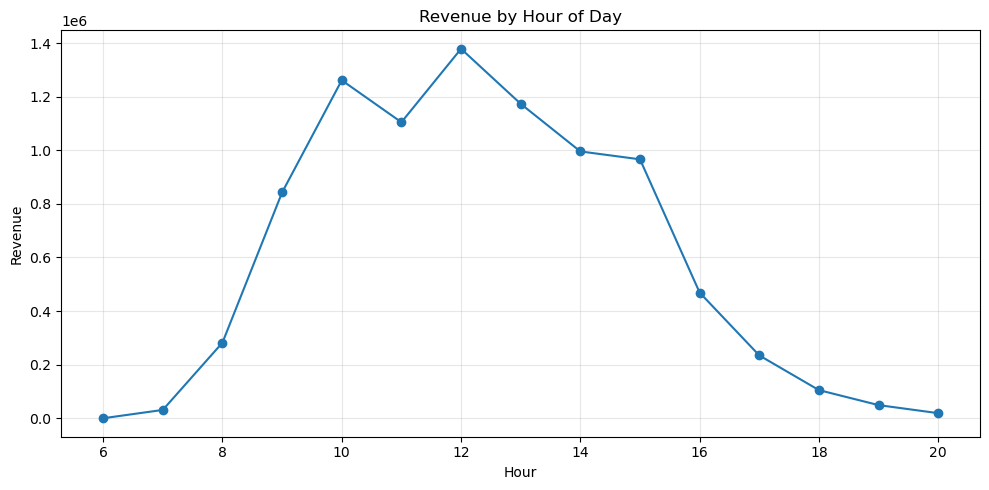

In [18]:
# Revenue by hour of day
rfm_df['Hour'] = rfm_df['InvoiceDate'].dt.hour

hourly_sales = (
    rfm_df.groupby('Hour')['Revenue']
    .sum()
)

print("Revenue by hour:")
print(hourly_sales)

plt.figure(figsize=(10, 5))
hourly_sales.plot(kind='line', marker='o')

plt.title('Revenue by Hour of Day')
plt.xlabel('Hour')
plt.ylabel('Revenue')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 4.4 Countries
The business is overwhelmingly **United Kingdom**-based; other countries contribute little revenue.

Top 10 countries by number of customers:
Country
United Kingdom    3920
Germany             94
France              87
Spain               30
Belgium             25
Switzerland         21
Portugal            19
Italy               14
Finland             12
Austria             11
Name: CustomerID, dtype: int64


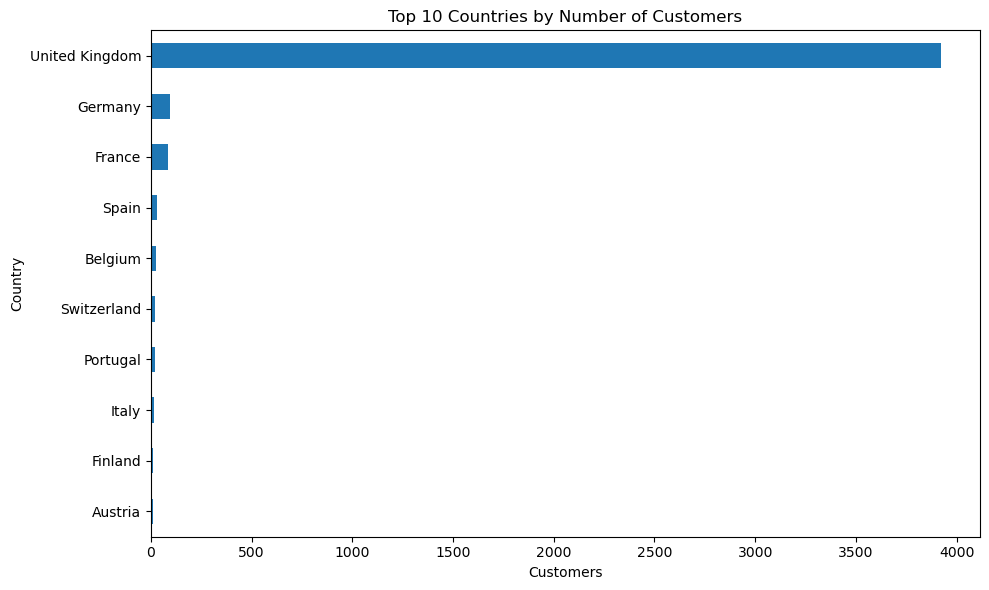

In [19]:
# Top 10 countries by number of customers
country_customers = (
    rfm_df.groupby('Country')['CustomerID']
    .nunique()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 countries by number of customers:")
print(country_customers)

plt.figure(figsize=(10, 6))
country_customers.sort_values().plot(kind='barh')

plt.title('Top 10 Countries by Number of Customers')
plt.xlabel('Customers')
plt.ylabel('Country')
plt.tight_layout()
plt.show()

Top 10 countries by orders:
Country
United Kingdom    16646
Germany             457
France              389
EIRE                260
Belgium              98
Netherlands          94
Spain                90
Australia            57
Portugal             57
Switzerland          51
Name: InvoiceNo, dtype: int64


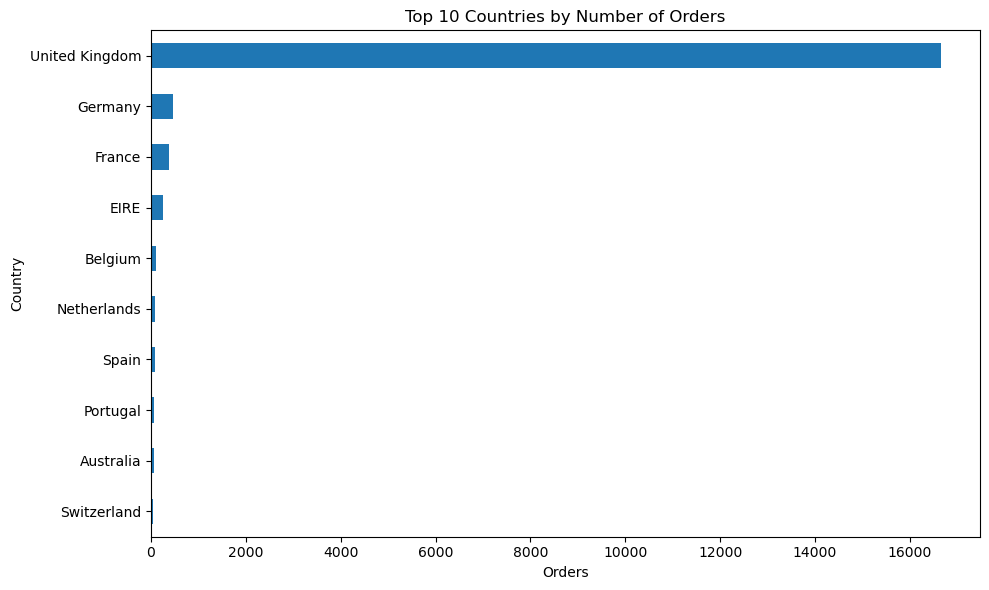

In [20]:
# Top 10 countries by number of orders
country_orders = (
    rfm_df.groupby('Country')['InvoiceNo']
    .nunique()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 countries by orders:")
print(country_orders)

plt.figure(figsize=(10, 6))
country_orders.sort_values().plot(kind='barh')

plt.title('Top 10 Countries by Number of Orders')
plt.xlabel('Orders')
plt.ylabel('Country')
plt.tight_layout()
plt.show()

Top 10 countries by revenue:
Country
United Kingdom    7308391.554
Netherlands        285446.340
EIRE               265545.900
Germany            228867.140
France             209024.050
Australia          138521.310
Spain               61577.110
Switzerland         56443.950
Belgium             41196.340
Sweden              38378.330
Name: Revenue, dtype: float64


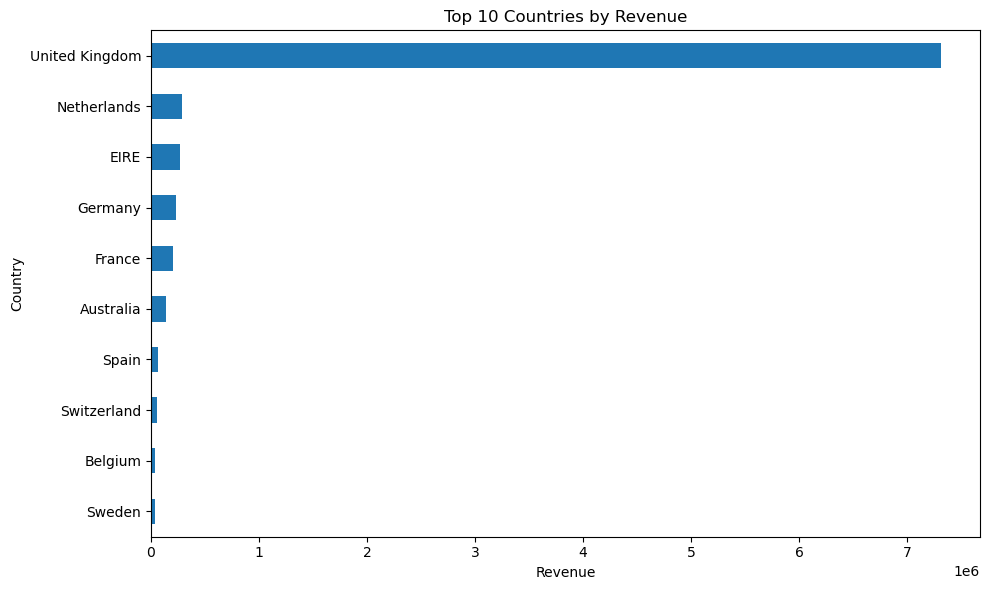

In [21]:
# Top 10 countries by revenue
country_revenue = (
    rfm_df.groupby('Country')['Revenue']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 countries by revenue:")
print(country_revenue)

plt.figure(figsize=(10, 6))
country_revenue.sort_values().plot(kind='barh')

plt.title('Top 10 Countries by Revenue')
plt.xlabel('Revenue')
plt.ylabel('Country')
plt.tight_layout()
plt.show()

### 4.5 Seasonality heat-map (Month x Day of week)
*Fixed:* the original code assigned 7 weekday names to a table with only 6 columns (no Saturday sales in the data).

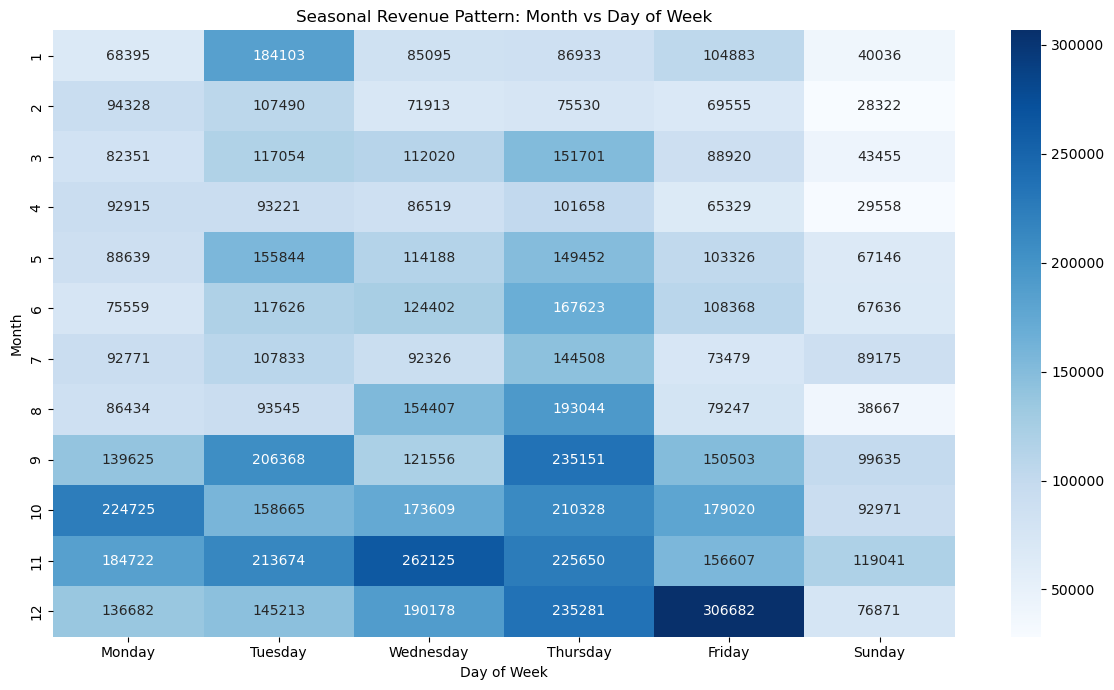

In [22]:
# Heat-map of revenue by month and weekday
import seaborn as sns

seasonal = (
    rfm_df.groupby(['Month', 'DayOfWeek'])['Revenue']
    .sum()
    .unstack()
)

# FIX: the data has NO Saturday rows, so the pivot has only 6 columns (0,1,2,3,4,6).
# Name each column from its own day number instead of assigning all 7 names at once.
seasonal.columns = [weekday_names[d] for d in seasonal.columns]

plt.figure(figsize=(12, 7))

sns.heatmap(
    seasonal,
    annot=True,
    fmt='.0f',
    cmap='Blues'
)

plt.title('Seasonal Revenue Pattern: Month vs Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Month')

plt.tight_layout()
plt.show()

---
## 5. Returns analysis
*Fixed:* the earlier code looked for `Quantity < 0` inside `rfm_df`, which had **already removed** those rows, so the result was always 0.

Returns are now taken from the **original `df`**. In this dataset a return/cancellation is an invoice whose number **starts with "C"** (its quantities are negative).
Other negative-quantity rows without a "C" (stock write-offs such as "damaged", with no customer and price 0) are internal adjustments, not customer returns, so they are excluded.

In [23]:
# FIX: returns come from the ORIGINAL df (rfm_df had all Quantity <= 0 rows removed -> 0 returns).
# A return / cancellation = invoice number starting with "C".
return_df = df[df['InvoiceNo'].astype(str).str.startswith('C')].copy()

print("Number of return rows:", len(return_df))

print("Percentage of transaction rows that are returns:",
      round(len(return_df) / len(df) * 100, 2), "%")

Number of return rows: 9288
Percentage of transaction rows that are returns: 1.71 %


In [24]:
# Total units returned (absolute value of the negative quantities)
return_quantity = abs(return_df['Quantity'].sum())

print("Total units returned:", return_quantity)

Total units returned: 277574


Top 10 returned products:
Description
PAPER CRAFT , LITTLE BIRDIE            80995
MEDIUM CERAMIC TOP STORAGE JAR         74494
ROTATING SILVER ANGELS T-LIGHT HLDR     9376
Manual                                  4066
FAIRY CAKE FLANNEL ASSORTED COLOUR      3150
PINK BLUE FELT CRAFT TRINKET BOX        2617
WHITE HANGING HEART T-LIGHT HOLDER      2578
GIN + TONIC DIET METAL SIGN             2030
HERB MARKER BASIL                       1527
FELTCRAFT DOLL MOLLY                    1447
Name: Quantity, dtype: int64


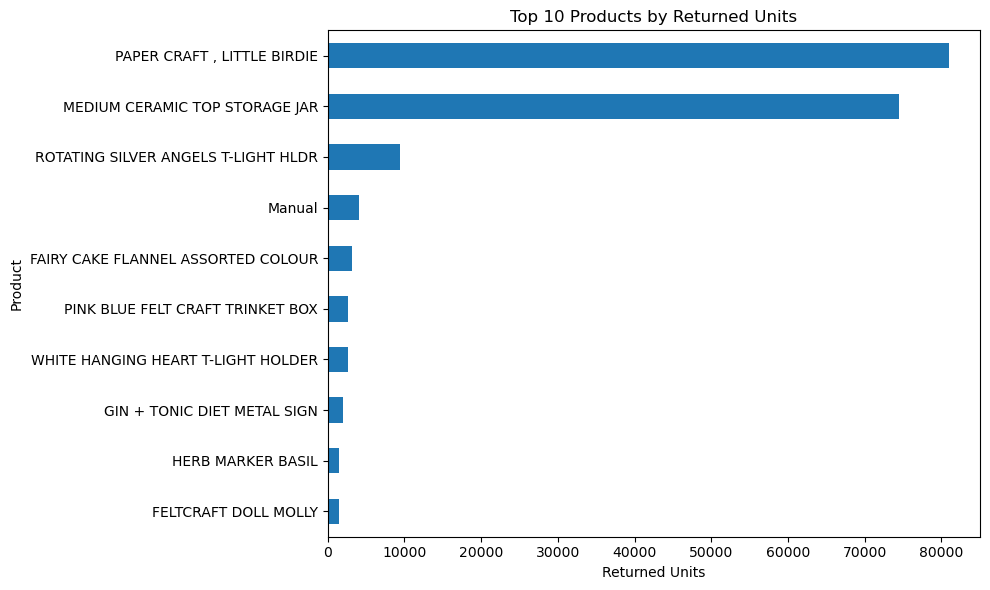

In [25]:
# Top 10 returned products (works now that return_df is not empty)
returned_products = (
    return_df.groupby('Description')['Quantity']
    .sum()
    .abs()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 returned products:")
print(returned_products)

plt.figure(figsize=(10, 6))
returned_products.sort_values().plot(kind='barh')

plt.title('Top 10 Products by Returned Units')
plt.xlabel('Returned Units')
plt.ylabel('Product')
plt.tight_layout()
plt.show()

Top 10 customers by returned units:
CustomerID
16446.0    80995
12346.0    74215
15838.0     9361
15749.0     9014
16029.0     8060
12931.0     4627
14607.0     3768
14911.0     3335
17949.0     2975
12901.0     2160
Name: Quantity, dtype: int64


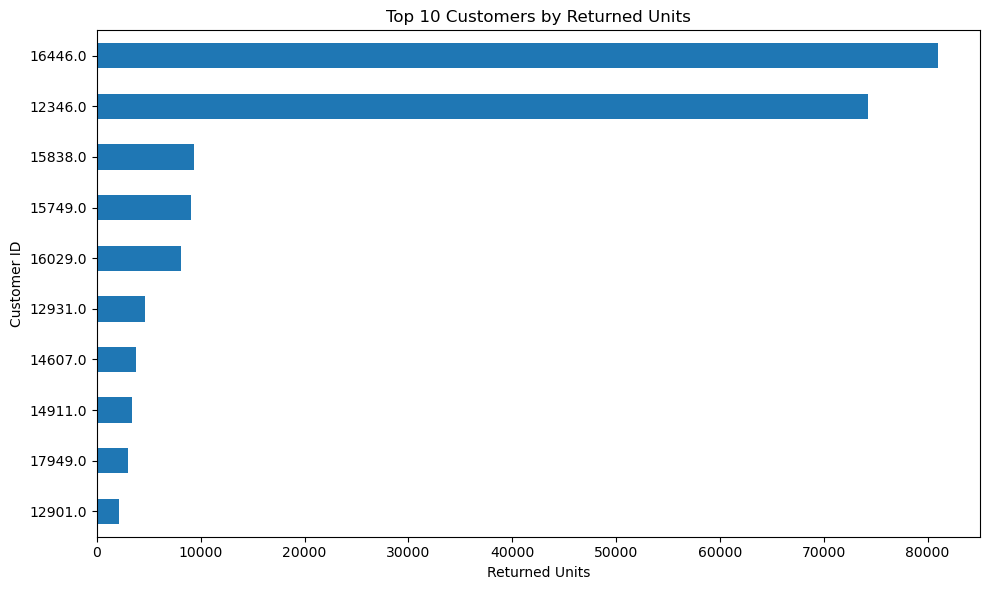

In [26]:
# Top 10 customers by returned units (rows without CustomerID are ignored by groupby)
returned_customers = (
    return_df.groupby('CustomerID')['Quantity']
    .sum()
    .abs()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 customers by returned units:")
print(returned_customers)

plt.figure(figsize=(10, 6))
returned_customers.sort_values().plot(kind='barh')

plt.title('Top 10 Customers by Returned Units')
plt.xlabel('Returned Units')
plt.ylabel('Customer ID')
plt.tight_layout()
plt.show()

---
## 6. Customer behaviour & business KPIs
### 6.1 Customer-level behaviour
Orders, units, revenue and average order value per customer. Half of the customers placed only 1-2 orders; a few placed 100+.

In [27]:
# One row per customer: orders, units, revenue, average line value
customer_behavior = (
    rfm_df.groupby('CustomerID')
    .agg(
        Orders=('InvoiceNo', 'nunique'),
        TotalUnits=('Quantity', 'sum'),
        TotalRevenue=('Revenue', 'sum'),
        AverageOrderValue=('Revenue', 'mean')
    )
)

print(customer_behavior.describe())

            Orders     TotalUnits   TotalRevenue  AverageOrderValue
count  4338.000000    4338.000000    4338.000000        4338.000000
mean      4.272015    1191.289073    2054.266460          68.350506
std       7.697998    5046.081546    8989.230441        1467.918896
min       1.000000       1.000000       3.750000           2.101286
25%       1.000000     160.000000     307.415000          12.365367
50%       2.000000     379.000000     674.485000          17.723119
75%       5.000000     992.750000    1661.740000          24.858417
max     209.000000  196915.000000  280206.020000       77183.600000


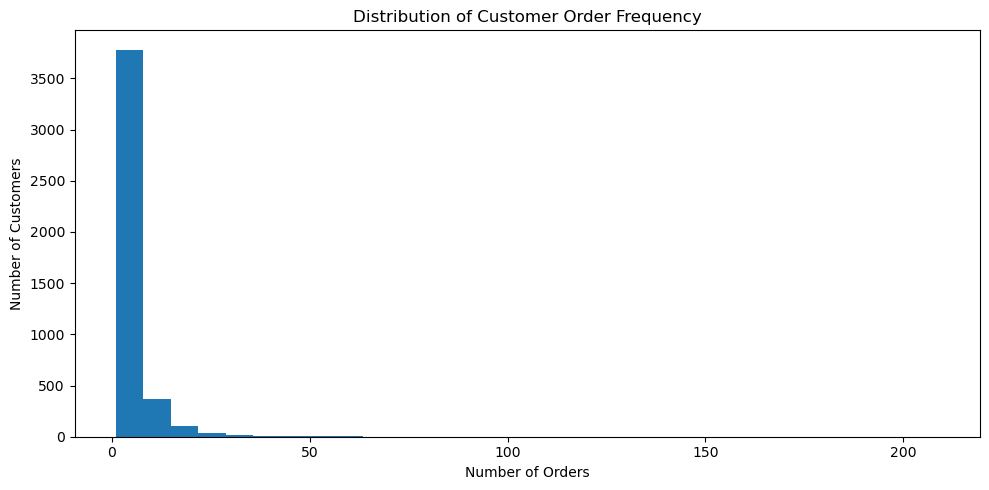

In [28]:
# Distribution of orders per customer (very right-skewed)
plt.figure(figsize=(10, 5))

plt.hist(
    customer_behavior['Orders'],
    bins=30
)

plt.title('Distribution of Customer Order Frequency')
plt.xlabel('Number of Orders')
plt.ylabel('Number of Customers')

plt.tight_layout()
plt.show()

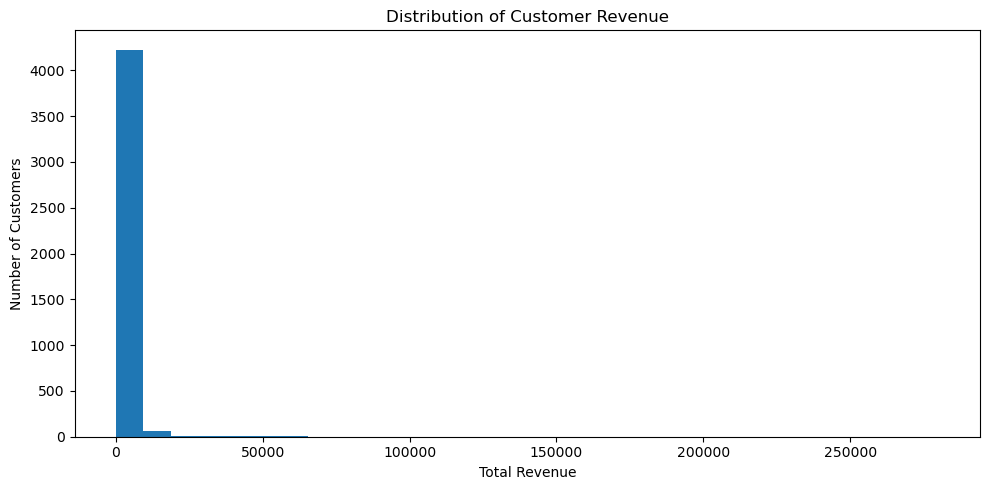

In [29]:
# Distribution of revenue per customer (very right-skewed)
plt.figure(figsize=(10, 5))

plt.hist(
    customer_behavior['TotalRevenue'],
    bins=30
)

plt.title('Distribution of Customer Revenue')
plt.xlabel('Total Revenue')
plt.ylabel('Number of Customers')

plt.tight_layout()
plt.show()

### 6.2 Bulk buyers
Customers and products with the highest average units per order - typical of wholesale / B2B behaviour.

In [30]:
# Customers with the highest average units per order
bulk_customers = (
    rfm_df.groupby('CustomerID')
    .agg(
        TotalUnits=('Quantity', 'sum'),
        Orders=('InvoiceNo', 'nunique'),
        Revenue=('Revenue', 'sum'),
        AvgUnitsPerOrder=('Quantity', 'sum')
    )
)

# Correct average units per order
bulk_customers['AvgUnitsPerOrder'] = (
    bulk_customers['TotalUnits'] /
    bulk_customers['Orders']
)

bulk_customers = bulk_customers.sort_values(
    'AvgUnitsPerOrder',
    ascending=False
)

print("Potential bulk-buying customers:")
print(bulk_customers.head(10))

Potential bulk-buying customers:
            TotalUnits  Orders    Revenue  AvgUnitsPerOrder
CustomerID                                                 
12346.0          74215       1   77183.60      74215.000000
16446.0          80997       2  168472.50      40498.500000
18251.0           7824       1    4314.72       7824.000000
15749.0          18028       3   44534.30       6009.333333
13135.0           4300       1    3096.00       4300.000000
16754.0           4280       1    2002.40       4280.000000
12415.0          77374      21  124914.53       3684.476190
12688.0           3028       1    4873.81       3028.000000
15372.0           2924       1    2007.40       2924.000000
13027.0          17280       6    6912.00       2880.000000


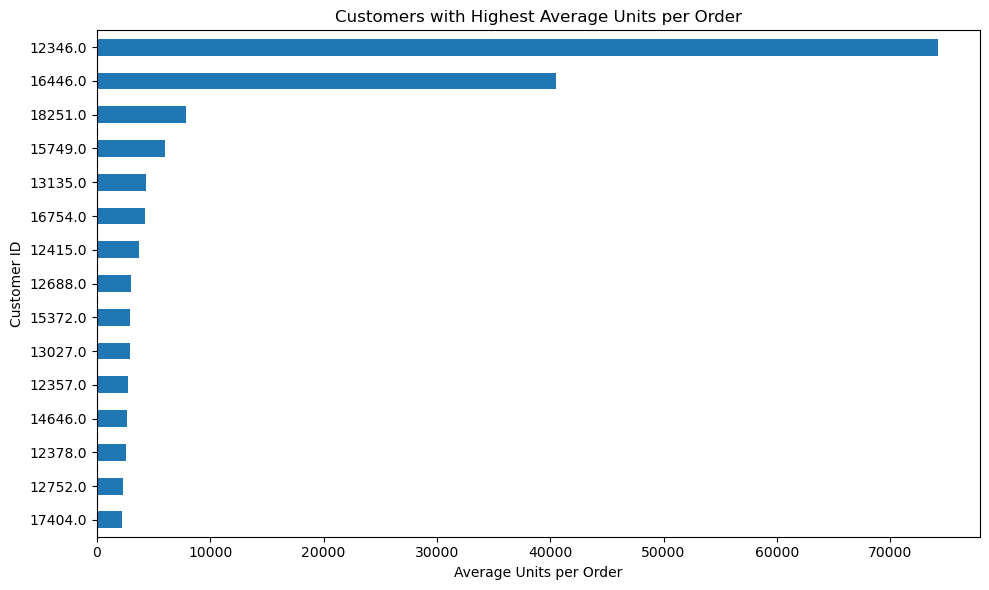

In [31]:
# Bar chart of the top 15 bulk-buying customers
top_bulk = bulk_customers.head(15)

plt.figure(figsize=(10, 6))

top_bulk['AvgUnitsPerOrder'].sort_values().plot(
    kind='barh'
)

plt.title('Customers with Highest Average Units per Order')
plt.xlabel('Average Units per Order')
plt.ylabel('Customer ID')

plt.tight_layout()
plt.show()

In [32]:
# Products with the highest average quantity per order
bulk_products = (
    rfm_df.groupby('Description')
    .agg(
        TotalUnits=('Quantity', 'sum'),
        Orders=('InvoiceNo', 'nunique')
    )
)

bulk_products['AvgUnitsPerOrder'] = (
    bulk_products['TotalUnits'] /
    bulk_products['Orders']
)

bulk_products = bulk_products.sort_values(
    'AvgUnitsPerOrder',
    ascending=False
)

print("Products with highest average quantity per order:")
print(bulk_products.head(10))

Products with highest average quantity per order:
                                     TotalUnits  Orders  AvgUnitsPerOrder
Description                                                              
PAPER CRAFT , LITTLE BIRDIE               80995       1      80995.000000
TEA TIME TEA TOWELS                        2600       2       1300.000000
GIRLS ALPHABET IRON ON PATCHES            12480      23        542.608696
MEDIUM CERAMIC TOP STORAGE JAR            77916     195        399.569231
ESSENTIAL BALM 3.5g TIN IN ENVELOPE        5856      17        344.470588
SET/5 RED SPOTTY LID GLASS BOWLS            288       1        288.000000
BOYS ALPHABET IRON ON PATCHES              1248       5        249.600000
SMALL CHINESE STYLE SCISSOR               13328      54        246.814815
MISELTOE HEART WREATH CREAM                 240       1        240.000000
MINI HIGHLIGHTER PENS                       840       4        210.000000


### 6.3 Traffic, order value and product concentration
Busiest hour, Average Order Value (AOV), basket size and the Pareto (80/20) analysis of products.

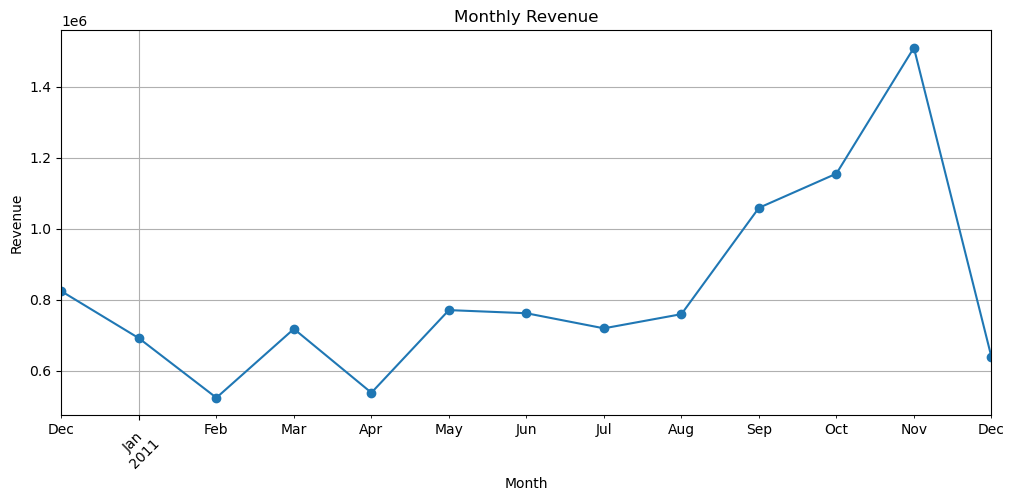

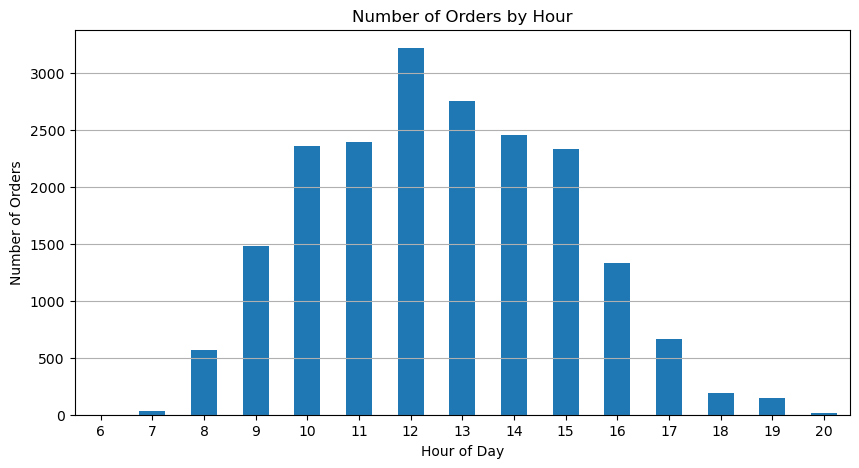

Busiest Hour: 12
Number of Orders: 3220


In [33]:
# Monthly revenue (again, on valid sales only) and orders per hour -> busiest hour
# Make sure InvoiceDate is datetime
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

# Create Revenue
df['Revenue'] = df['Quantity'] * df['UnitPrice']

# Remove invalid purchases
sales_df = df[
    (df['Quantity'] > 0) &
    (df['UnitPrice'] > 0)
].copy()

# -----------------------------
# Monthly Revenue
# -----------------------------

sales_df['Month'] = sales_df['InvoiceDate'].dt.to_period('M')

monthly_revenue = sales_df.groupby('Month')['Revenue'].sum()

plt.figure(figsize=(12, 5))
monthly_revenue.plot(kind='line', marker='o')

plt.title('Monthly Revenue')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()


# -----------------------------
# Hourly Traffic
# -----------------------------

sales_df['Hour'] = sales_df['InvoiceDate'].dt.hour

# Count unique invoices instead of rows
hourly_orders = sales_df.groupby('Hour')['InvoiceNo'].nunique()

plt.figure(figsize=(10, 5))
hourly_orders.plot(kind='bar')

plt.title('Number of Orders by Hour')
plt.xlabel('Hour of Day')
plt.ylabel('Number of Orders')
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.show()


# Display the busiest hour
busiest_hour = hourly_orders.idxmax()
busiest_orders = hourly_orders.max()

print("Busiest Hour:", busiest_hour)
print("Number of Orders:", busiest_orders)

Average Order Value: 534.4
Average Basket Size: 279.98


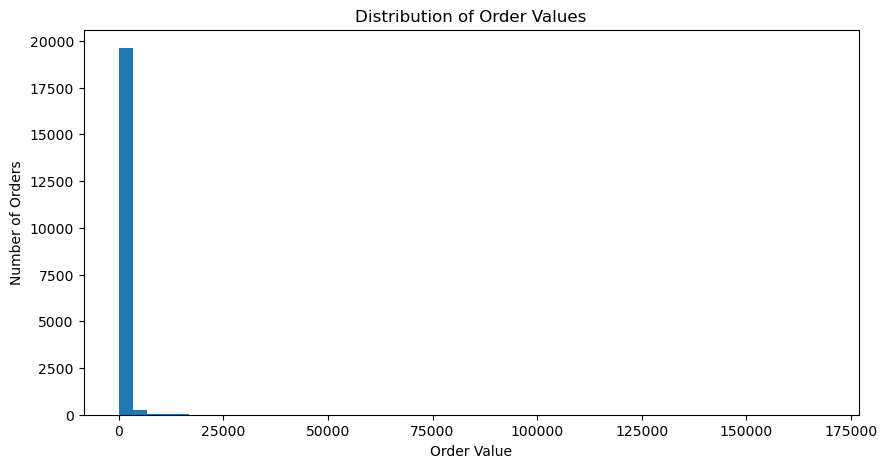

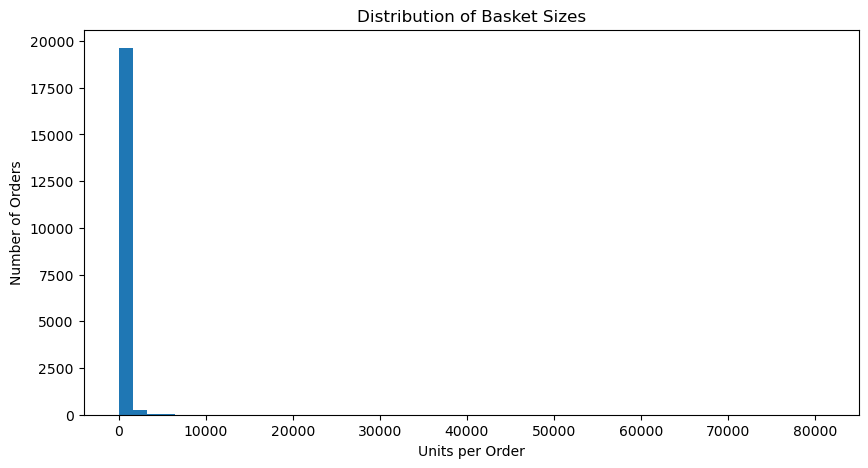


Largest Orders:
           OrderValue  BasketSize
InvoiceNo                        
581483      168469.60       80995
541431       77183.60       74215
574941       52940.94       14149
576365       50653.91       13956
556444       38970.00          60
567423       31698.16       12572
556917       22775.93       15049
572209       22206.00        1920
567381       22104.80        6760
563614       21880.44       12196


In [34]:
# Average Order Value, basket size and their distributions; largest orders
# Make sure InvoiceDate is datetime
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

# Create Revenue
df['Revenue'] = df['Quantity'] * df['UnitPrice']

# Keep valid purchases
sales_df = df[
    (df['Quantity'] > 0) &
    (df['UnitPrice'] > 0)
].copy()

# -----------------------------
# Calculate metrics per order
# -----------------------------

order_metrics = sales_df.groupby('InvoiceNo').agg(
    OrderValue=('Revenue', 'sum'),
    BasketSize=('Quantity', 'sum')
)

# -----------------------------
# Average Order Value
# -----------------------------

AOV = order_metrics['OrderValue'].mean()

print("Average Order Value:", round(AOV, 2))

# -----------------------------
# Average Basket Size
# -----------------------------

average_basket = order_metrics['BasketSize'].mean()

print("Average Basket Size:", round(average_basket, 2))


# -----------------------------
# AOV Distribution
# -----------------------------

plt.figure(figsize=(10, 5))
plt.hist(order_metrics['OrderValue'], bins=50)

plt.title('Distribution of Order Values')
plt.xlabel('Order Value')
plt.ylabel('Number of Orders')
plt.show()


# -----------------------------
# Basket Size Distribution
# -----------------------------

plt.figure(figsize=(10, 5))
plt.hist(order_metrics['BasketSize'], bins=50)

plt.title('Distribution of Basket Sizes')
plt.xlabel('Units per Order')
plt.ylabel('Number of Orders')
plt.show()


# -----------------------------
# Identify large orders
# -----------------------------

print("\nLargest Orders:")
print(order_metrics.sort_values('OrderValue', ascending=False).head(10))

Top 20% of products generate: 79.45 % of total revenue


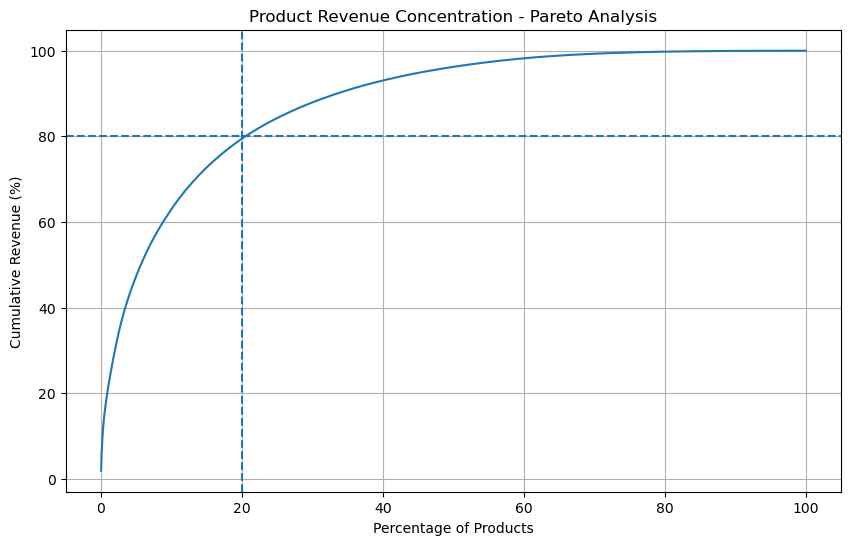

In [35]:
# Pareto analysis: share of revenue from the top 20 % of products
# Create Revenue
df['Revenue'] = df['Quantity'] * df['UnitPrice']

# Keep valid purchases
sales_df = df[
    (df['Quantity'] > 0) &
    (df['UnitPrice'] > 0)
].copy()

# Revenue per product
product_revenue = (
    sales_df.groupby('StockCode')['Revenue']
    .sum()
    .sort_values(ascending=False)
)

# Convert to DataFrame
product_revenue_df = product_revenue.reset_index()

# Cumulative revenue
product_revenue_df['CumulativeRevenue'] = (
    product_revenue_df['Revenue'].cumsum()
)

total_revenue = product_revenue_df['Revenue'].sum()

product_revenue_df['CumulativeRevenuePercent'] = (
    product_revenue_df['CumulativeRevenue']
    / total_revenue * 100
)

# Percentage of products
product_revenue_df['ProductPercent'] = (
    np.arange(1, len(product_revenue_df) + 1)
    / len(product_revenue_df) * 100
)

# Top 20% of products
top_20_index = int(len(product_revenue_df) * 0.20)

top_20_revenue_percent = (
    product_revenue_df.iloc[top_20_index - 1]
    ['CumulativeRevenuePercent']
)

print(
    "Top 20% of products generate:",
    round(top_20_revenue_percent, 2),
    "% of total revenue"
)

# Pareto Curve
plt.figure(figsize=(10, 6))

plt.plot(
    product_revenue_df['ProductPercent'],
    product_revenue_df['CumulativeRevenuePercent']
)

plt.axvline(20, linestyle='--')
plt.axhline(80, linestyle='--')

plt.title('Product Revenue Concentration - Pareto Analysis')
plt.xlabel('Percentage of Products')
plt.ylabel('Cumulative Revenue (%)')

plt.grid(True)
plt.show()

### 6.4 Potential dead stock
Products that sold historically but had **zero sales in the last 90 days** of the data.

In [36]:
# Dead-stock candidates: sold before, but nothing in the last 90 days
# Make sure InvoiceDate is datetime
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

# Create Revenue
df['Revenue'] = df['Quantity'] * df['UnitPrice']

# -----------------------------
# Find the latest date
# -----------------------------

latest_date = df['InvoiceDate'].max()

# Last 90 days
last_90_days = latest_date - pd.Timedelta(days=90)

print("Latest Date:", latest_date)
print("90 Days Before:", last_90_days)


# -----------------------------
# Historical sales
# -----------------------------

historical_sales = (
    df[df['Quantity'] > 0]
    .groupby('StockCode')['Quantity']
    .sum()
    .rename('HistoricalUnitsSold')
)


# -----------------------------
# Recent sales
# -----------------------------

recent_sales = (
    df[
        (df['InvoiceDate'] >= last_90_days) &
        (df['Quantity'] > 0)
    ]
    .groupby('StockCode')['Quantity']
    .sum()
    .rename('Recent90DaysUnits')
)


# -----------------------------
# Combine the results
# -----------------------------

dead_stock = pd.concat(
    [historical_sales, recent_sales],
    axis=1
).fillna(0)


# -----------------------------
# Identify potential dead stock
# -----------------------------

dead_stock_candidates = dead_stock[
    (dead_stock['HistoricalUnitsSold'] > 0) &
    (dead_stock['Recent90DaysUnits'] == 0)
].copy()


# Sort by historical sales
dead_stock_candidates = dead_stock_candidates.sort_values(
    'HistoricalUnitsSold',
    ascending=False
)


print("\nPotential Dead Stock:")
print(dead_stock_candidates.head(20))

Latest Date: 2011-12-09 12:50:00
90 Days Before: 2011-09-10 12:50:00

Potential Dead Stock:
           HistoricalUnitsSold  Recent90DaysUnits
StockCode                                        
18007                     5884                0.0
47556B                    3900                0.0
10133                     2867                0.0
22855                     2644                0.0
17096                     2545                0.0
21399                     2066                0.0
21033                     2032                0.0
21069                     1956                0.0
22088                     1894                0.0
37342                     1571                0.0
21398                     1532                0.0
85132C                    1520                0.0
21870                     1415                0.0
79030G                    1409                0.0
22444                     1383                0.0
84611B                    1287                0.0
22245   

---
## 7. RFM analysis
Each customer is described by three numbers:

| Metric | Meaning | Calculation | Better when |
|--------|---------|-------------|-------------|
| **R**ecency | How recently did they buy? | Days between the snapshot date (last invoice + 1 day) and their last purchase | lower |
| **F**requency | How often do they buy? | Number of distinct invoices | higher |
| **M**onetary | How much do they spend? | Total revenue | higher |

Each metric is then converted into a **1-5 score** using quintiles (5 = best). Combined they give an RFM code such as `545`.

*Fixed:* Frequency is very concentrated (over half of customers bought once), so `qcut` collapsed to only 4 groups and no customer could ever have `F = 5`.
Using `rank(method='first')` first breaks ties and gives 5 equal-sized groups, which the Champions definition (R=5, F=5, M=5) requires.

In [37]:
# Build the RFM table: metrics -> 1-5 scores -> combined RFM code
# ==========================================
# 1. Prepare the data
# ==========================================

rfm_df = df.copy()

rfm_df['InvoiceDate'] = pd.to_datetime(rfm_df['InvoiceDate'])

# Remove missing CustomerID
rfm_df = rfm_df.dropna(subset=['CustomerID'])

# Keep valid purchases only
rfm_df = rfm_df[
    (rfm_df['Quantity'] > 0) &
    (rfm_df['UnitPrice'] > 0)
].copy()

# Calculate Revenue
rfm_df['Revenue'] = (
    rfm_df['Quantity'] * rfm_df['UnitPrice']
)


# ==========================================
# 2. Snapshot date
# ==========================================

snapshot_date = (
    rfm_df['InvoiceDate'].max()
    + pd.Timedelta(days=1)
)


# ==========================================
# 3. Calculate RFM metrics
# ==========================================

RFM = rfm_df.groupby('CustomerID').agg(
    Recency=(
        'InvoiceDate',
        lambda x: (snapshot_date - x.max()).days
    ),

    Frequency=(
        'InvoiceNo',
        'nunique'
    ),

    Monetary=(
        'Revenue',
        'sum'
    )
).reset_index()


# ==========================================
# 4. RFM Scoring
# ==========================================

# Recency
# Lower Recency = better
RFM['R_Score'] = pd.qcut(
    RFM['Recency'],
    q=5,
    labels=False,
    duplicates='drop'
)

# Reverse the score
RFM['R_Score'] = (
    RFM['R_Score'].max() - RFM['R_Score'] + 1
)


# Frequency
# Higher Frequency = better
# FIX: many customers share Frequency = 1, so plain qcut collapses to 4 bins (scores 1-4 only).
# rank(method='first') breaks the ties so that 5 equal-sized groups (1-5) can be created.
RFM['F_Score'] = pd.qcut(
    RFM['Frequency'].rank(method='first'),
    q=5,
    labels=False
)

RFM['F_Score'] = RFM['F_Score'] + 1


# Monetary
# Higher Monetary = better
RFM['M_Score'] = pd.qcut(
    RFM['Monetary'],
    q=5,
    labels=False,
    duplicates='drop'
)

RFM['M_Score'] = RFM['M_Score'] + 1


# ==========================================
# 5. Convert scores to integers
# ==========================================

RFM['R_Score'] = RFM['R_Score'].astype(int)
RFM['F_Score'] = RFM['F_Score'].astype(int)
RFM['M_Score'] = RFM['M_Score'].astype(int)


# ==========================================
# 6. Combine RFM scores
# ==========================================

RFM['RFM_Score'] = (
    RFM['R_Score'].astype(str) +
    RFM['F_Score'].astype(str) +
    RFM['M_Score'].astype(str)
)


# ==========================================
# 7. Display results
# ==========================================

print(RFM.head(10))

print("\nScore distributions:")

print("\nRecency:")
print(RFM['R_Score'].value_counts().sort_index())

print("\nFrequency:")
print(RFM['F_Score'].value_counts().sort_index())

print("\nMonetary:")
print(RFM['M_Score'].value_counts().sort_index())

print("\nRFM Scores:")
print(RFM['RFM_Score'].value_counts().head(20))

   CustomerID  Recency  Frequency  Monetary  R_Score  F_Score  M_Score  \
0     12346.0      326          1  77183.60        1        1        5   
1     12347.0        2          7   4310.00        5        5        5   
2     12348.0       75          4   1797.24        2        4        4   
3     12349.0       19          1   1757.55        4        1        4   
4     12350.0      310          1    334.40        1        1        2   
5     12352.0       36          8   2506.04        3        5        5   
6     12353.0      204          1     89.00        1        1        1   
7     12354.0      232          1   1079.40        1        1        4   
8     12355.0      214          1    459.40        1        1        2   
9     12356.0       23          3   2811.43        4        3        5   

  RFM_Score  
0       115  
1       555  
2       244  
3       414  
4       112  
5       355  
6       111  
7       114  
8       112  
9       435  

Score distributions:

Recency:

---
## 8. K-Means clustering (K = 5)
Steps: select R, F, M -> `log1p` to reduce skew -> `StandardScaler` so all three have the same weight -> K-Means.

* The **Elbow** and **Silhouette** diagnostics are kept for reference (K = 2 to 10).
* The number of clusters is now **fixed at K = 5** (previously the code picked the K with the highest silhouette, which was K = 2).
  Five groups are more granular and give enough segments to build the strategies in Section 9. A higher K normally lowers the silhouette score a little; this is the expected trade-off for more actionable segments.

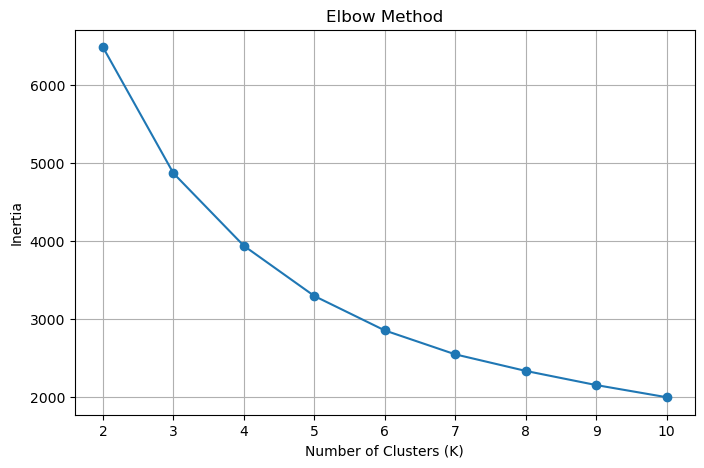

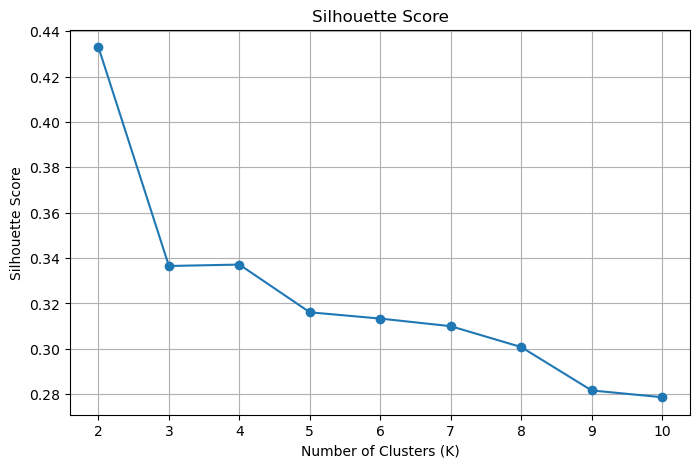

K-Means Evaluation:
    K      Inertia  Silhouette Score
0   2  6481.225323          0.432940
1   3  4867.846645          0.336510
2   4  3938.509954          0.337134
3   5  3295.976329          0.316097
4   6  2855.011247          0.313329
5   7  2548.914324          0.309975
6   8  2336.777508          0.300782
7   9  2155.648193          0.281653
8  10  1999.903270          0.278665

Selected K: 5

Final Silhouette Score: 0.3161

Cluster Summary:
         Customers  Avg_Recency  Avg_Frequency  Avg_Monetary
Cluster                                                     
0              851        27.99           1.61        389.04
1              944        18.55           5.80       2168.93
2             1185       211.15           1.21        277.20
3              343        12.19          20.63      13780.08
4             1015       104.14           3.13       1455.97

Customers per Cluster:
Cluster
0     851
1     944
2    1185
3     343
4    1015
Name: count, dtype: int64


In [38]:
# ==========================================
# RFM CUSTOMER SEGMENTATION USING K-MEANS
# ==========================================


from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


# ==========================================
# 1. Select RFM Features
# ==========================================

rfm_features = RFM[
    ['Recency', 'Frequency', 'Monetary']
].copy()


# ==========================================
# 2. Log Transformation
# ==========================================
# Reduces the effect of extreme values
# and handles skewed RFM distributions.

rfm_log = np.log1p(rfm_features)


# ==========================================
# 3. StandardScaler
# ==========================================
# Puts Recency, Frequency and Monetary
# on the same scale.

scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(rfm_log)


# ==========================================
# 4. Elbow Method
# ==========================================

inertia = []

K = range(2, 11)

for k in K:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(rfm_scaled)

    # Correct attribute: inertia_
    inertia.append(kmeans.inertia_)


# Plot Elbow Curve

plt.figure(figsize=(8, 5))

plt.plot(
    K,
    inertia,
    marker='o'
)

plt.title('Elbow Method')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.xticks(K)
plt.grid(True)

plt.show()


# ==========================================
# 5. Silhouette Score
# ==========================================

silhouette_scores = []

for k in K:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(rfm_scaled)

    score = silhouette_score(
        rfm_scaled,
        labels
    )

    silhouette_scores.append(score)


# Plot Silhouette Scores

plt.figure(figsize=(8, 5))

plt.plot(
    K,
    silhouette_scores,
    marker='o'
)

plt.title('Silhouette Score')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.xticks(K)
plt.grid(True)

plt.show()


# ==========================================
# 6. Compare K Values
# ==========================================

results = pd.DataFrame({
    'K': list(K),
    'Inertia': inertia,
    'Silhouette Score': silhouette_scores
})

print("K-Means Evaluation:")
print(results)


# ==========================================
# 7. Choose K
# ==========================================
# CHANGED: K is fixed to 5 (business requirement).
# The elbow / silhouette results above are kept as diagnostics only.
# (Before: best_k = list(K)[np.argmax(silhouette_scores)]  ->  K = 2)

best_k = 5

print("\nSelected K:", best_k)


# ==========================================
# 8. Train Final K-Means Model
# ==========================================

final_kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

RFM['Cluster'] = final_kmeans.fit_predict(
    rfm_scaled
)


# ==========================================
# 9. Final Silhouette Score
# ==========================================

final_silhouette = silhouette_score(
    rfm_scaled,
    RFM['Cluster']
)

print(
    "\nFinal Silhouette Score:",
    round(final_silhouette, 4)
)


# ==========================================
# 10. Cluster Summary
# ==========================================

cluster_summary = RFM.groupby('Cluster').agg(
    Customers=('CustomerID', 'count'),
    Avg_Recency=('Recency', 'mean'),
    Avg_Frequency=('Frequency', 'mean'),
    Avg_Monetary=('Monetary', 'mean')
).round(2)

print("\nCluster Summary:")
print(cluster_summary)


# ==========================================
# 11. Cluster Sizes
# ==========================================

cluster_sizes = (
    RFM['Cluster']
    .value_counts()
    .sort_index()
)

print("\nCustomers per Cluster:")
print(cluster_sizes)

---
## 9. Business Translation Matrix
Cluster numbers (0-4) are arbitrary labels. Here every cluster is translated into a **business segment** and a **marketing action**.

**How the matching works**

1. For each cluster, compute its average R, F and M *scores* (1-5).
2. Compare it with the ideal score profile of each segment:

| Segment | Ideal profile | Strategy |
|---------|---------------|----------|
| **Champions** | R=5, F=5, M=5 | Most profitable buyers: loyalty perks, exclusive early access, brand referral programs |
| **Loyal Customers** | R=4, F=4, M=4 | Consistent regular spenders: maximise revenue with cross-selling of related catalogue segments |
| **At-Risk / High-Value Churn** | Low R, High F, High M | Heavy historic spenders who stopped buying: immediate direct win-back email offers or strong promotional price triggers |
| **New Inflow** | High R, Low F, Low M | Recent first-time purchasers: welcome discount sequence to trigger a second purchase |
| **Lost / Low-Value** *(5th cluster)* | Low R, Low F, Low M | Inactive, low-spend customers: low-cost automated reactivation only |

3. Each cluster is matched to **exactly one** segment (best overall fit, using the Hungarian algorithm), so no two clusters get the same label.
   `Match_Distance` shows how close a cluster is to its ideal profile (smaller = better fit).

> The fifth segment (*Lost / Low-Value*) is needed because K = 5 produces five groups but four strategies were specified. Its name and action are my addition and can be changed.

In [39]:
# ==========================================
# BUSINESS TRANSLATION MATRIX (K = 5)
# ==========================================

from scipy.optimize import linear_sum_assignment
from IPython.display import display

pd.set_option('display.max_colwidth', None)
pd.set_option('display.width', 200)


# ------------------------------------------
# 1. Average R, F, M score of every cluster
# ------------------------------------------

cluster_rfm = RFM.groupby('Cluster').agg(
    Avg_R=('R_Score', 'mean'),
    Avg_F=('F_Score', 'mean'),
    Avg_M=('M_Score', 'mean')
).round(2)


# ------------------------------------------
# 2. Ideal (R, F, M) profile of each segment
# ------------------------------------------

segment_profiles = {
    'Champions':                  (5.0, 5.0, 5.0),
    'Loyal Customers':            (4.0, 4.0, 4.0),
    'At-Risk / High-Value Churn': (1.5, 4.0, 4.0),   # Low R, High F, High M
    'New Inflow':                 (4.5, 1.5, 1.5),   # High R, Low F, Low M
    'Lost / Low-Value':           (1.0, 1.0, 1.0)    # Low R, Low F, Low M
}

segment_names  = list(segment_profiles.keys())
profile_matrix = np.array(list(segment_profiles.values()))


# ------------------------------------------
# 3. Distance: every cluster vs every profile
# ------------------------------------------

cluster_values = cluster_rfm[['Avg_R', 'Avg_F', 'Avg_M']].values

distance = np.linalg.norm(
    cluster_values[:, None, :] - profile_matrix[None, :, :],
    axis=2
)


# ------------------------------------------
# 4. One-to-one best match (each cluster -> a different segment)
# ------------------------------------------

row_idx, col_idx = linear_sum_assignment(distance)

cluster_rfm['Segment'] = [segment_names[j] for j in col_idx]
cluster_rfm['Match_Distance'] = distance[row_idx, col_idx].round(2)

print("Cluster -> Business Segment")
display(cluster_rfm)


# ------------------------------------------
# 5. Add segment + strategy to every customer
# ------------------------------------------

strategy = {
    'Champions':
        'Reward with loyalty perks, exclusive early access, and brand referral programs.',

    'Loyal Customers':
        'Maximize revenue via cross-selling related product catalog segments.',

    'At-Risk / High-Value Churn':
        'Deploy immediate direct win-back email offers or strong promotional price triggers.',

    'New Inflow':
        'Onboard via welcome discount sequences to trigger a secondary purchase.',

    'Lost / Low-Value':
        'Low-cost automated reactivation email; stop paid spend if there is no response.'
}

RFM['Segment'] = RFM['Cluster'].map(cluster_rfm['Segment'])
RFM['Marketing_Strategy'] = RFM['Segment'].map(strategy)


# ------------------------------------------
# 6. Final Business Translation Matrix
# ------------------------------------------

business_summary = RFM.groupby('Segment').agg(
    Customers=('CustomerID', 'count'),
    Avg_Recency=('Recency', 'mean'),
    Avg_Frequency=('Frequency', 'mean'),
    Avg_Monetary=('Monetary', 'mean'),
    Total_Revenue=('Monetary', 'sum')
).round(2)

business_summary['Customers_%'] = (
    business_summary['Customers'] / business_summary['Customers'].sum() * 100
).round(1)

business_summary['Revenue_%'] = (
    business_summary['Total_Revenue'] / business_summary['Total_Revenue'].sum() * 100
).round(1)

# Show the segments in the business order
business_summary = business_summary.reindex(segment_names)

business_summary['Marketing_Strategy'] = business_summary.index.map(strategy)

print("\nBusiness Translation Matrix:")
display(business_summary)

Cluster -> Business Segment


,Avg_R,Avg_F,Avg_M,Segment,Match_Distance
Cluster,,,,,
0,3.89,2.18,1.99,New Inflow,1.04
1,4.32,4.38,4.27,Loyal Customers,0.57
2,1.46,1.69,1.61,Lost / Low-Value,1.03
3,4.65,4.99,4.99,Champions,0.35
4,2.33,3.26,3.62,At-Risk / High-Value Churn,1.18



Business Translation Matrix:


,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Total_Revenue,Customers_%,Revenue_%,Marketing_Strategy
Segment,,,,,,,,
Champions,343,12.19,20.63,13780.08,4726565.90,7.9,53.0,"Reward with loyalty perks, exclusive early access, and brand referral programs."
Loyal Customers,944,18.55,5.80,2168.93,2047471.01,21.8,23.0,Maximize revenue via cross-selling related product catalog segments.
At-Risk / High-Value Churn,1015,104.14,3.13,1455.97,1477807.83,23.4,16.6,Deploy immediate direct win-back email offers or strong promotional price triggers.
New Inflow,851,27.99,1.61,389.04,331075.46,19.6,3.7,Onboard via welcome discount sequences to trigger a secondary purchase.
Lost / Low-Value,1185,211.15,1.21,277.20,328487.70,27.3,3.7,Low-cost automated reactivation email; stop paid spend if there is no response.


### 9.1 Customers vs revenue by segment
Compare the size of each segment (share of customers) with its economic weight (share of revenue).
A segment whose revenue share is far above its customer share is where the money is concentrated.

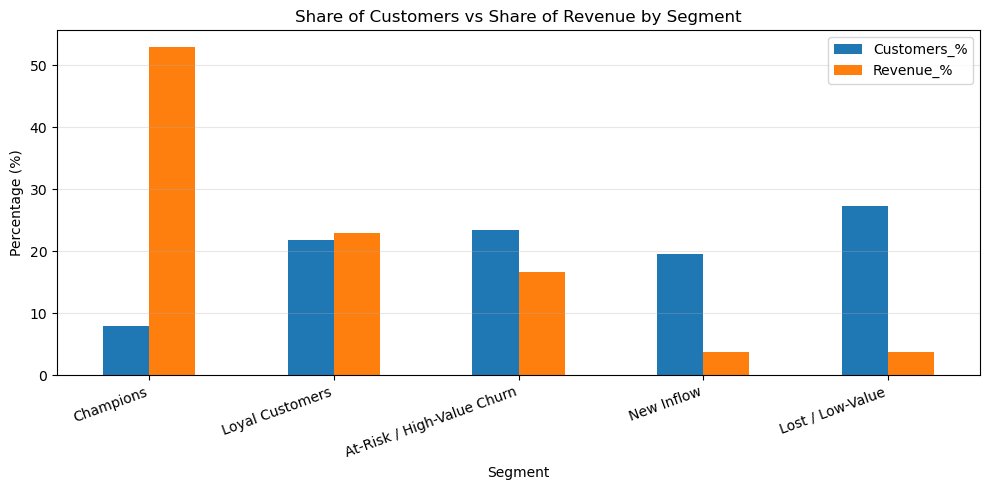

In [40]:
# Share of customers vs share of revenue for each segment
share = business_summary[['Customers_%', 'Revenue_%']]

ax = share.plot(kind='bar', figsize=(10, 5))

ax.set_title('Share of Customers vs Share of Revenue by Segment')
ax.set_xlabel('Segment')
ax.set_ylabel('Percentage (%)')
plt.xticks(rotation=20, ha='right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

---
## 10. Business recommendations and conclusion
### 10.1 Key numbers (computed from your data)
The cell below prints the headline numbers that support the recommendations, so they stay correct whenever the notebook is re-run.

In [41]:
# Headline numbers used in the recommendations
print("Revenue and customers by segment")
print("-" * 60)

for seg, row in business_summary.iterrows():
    print(f"{seg:<28} {row['Customers_%']:>5.1f}% of customers  ->  {row['Revenue_%']:>5.1f}% of revenue")

print()

top_two = business_summary.loc[['Champions', 'Loyal Customers'], 'Revenue_%'].sum()
print(f"Champions + Loyal Customers generate {top_two:.1f}% of revenue.")

risk = business_summary.loc['At-Risk / High-Value Churn']
print(f"At-Risk customers: {int(risk['Customers'])} customers, "
      f"average {risk['Avg_Recency']:.0f} days since last purchase, "
      f"average lifetime spend {risk['Avg_Monetary']:,.0f} "
      f"(total {risk['Total_Revenue']:,.0f} of historical revenue at stake).")

new = business_summary.loc['New Inflow']
print(f"New Inflow: {int(new['Customers'])} customers, average {new['Avg_Frequency']:.1f} orders so far.")

print()
print(f"Return/cancellation rows: {len(return_df):,} "
      f"({len(return_df) / len(df) * 100:.2f}% of all transaction rows)")

Revenue and customers by segment
------------------------------------------------------------
Champions                      7.9% of customers  ->   53.0% of revenue
Loyal Customers               21.8% of customers  ->   23.0% of revenue
At-Risk / High-Value Churn    23.4% of customers  ->   16.6% of revenue
New Inflow                    19.6% of customers  ->    3.7% of revenue
Lost / Low-Value              27.3% of customers  ->    3.7% of revenue

Champions + Loyal Customers generate 76.0% of revenue.
At-Risk customers: 1015 customers, average 104 days since last purchase, average lifetime spend 1,456 (total 1,477,808 of historical revenue at stake).
New Inflow: 851 customers, average 1.6 orders so far.

Return/cancellation rows: 9,288 (1.71% of all transaction rows)


### 10.2 Recommendations

**A. Segment actions (from the Business Translation Matrix)**

1. **Champions** - Protect them first: loyalty tiers, early access to new collections, a referral programme, and a named account contact for the largest wholesale-type buyers. They are the highest-value group, so retention here is worth more than any acquisition campaign.
2. **Loyal Customers** - Grow basket size with cross-selling (related product families, bundles, "customers also bought") and offer a small incentive to move them toward Champion behaviour (one more order per quarter).
3. **At-Risk / High-Value Churn** - Highest-priority win-back target: they used to buy often and spend a lot but have gone quiet. Send an immediate personalised win-back email, follow up with a time-limited promotion, and have sales contact the biggest accounts directly. Measure the win-back rate and cost per reactivated customer.
4. **New Inflow** - The second purchase decides whether they become Loyal customers. Run a welcome sequence (thank-you, best sellers, a discount valid for a second order within ~30 days).
5. **Lost / Low-Value** - Do not spend heavily. Use one low-cost automated reactivation email; if there is no response, remove them from paid campaigns.

**B. Insights from the exploratory analysis**

6. **Plan for the Q4 peak.** Revenue climbs sharply from September and peaks in October-November (about 0.95M / 1.04M / 1.16M, versus roughly 0.45-0.68M per month from January to August). Secure inventory and start campaigns in August-September.
7. **Time your communications.** Thursday is the strongest weekday and Sunday the weakest; order activity peaks between 10:00 and 15:00, with 12:00 the busiest hour. Send emails on Tuesday-Thursday mornings, and schedule staffing and site maintenance around the peak hours.
8. **Protect the top products.** About 79 % of revenue comes from the top 20 % of products (close to the 80/20 rule). Keep these permanently in stock; a stock-out costs far more than on other lines.
9. **Clear dead stock.** Products with sales history but zero sales in the last 90 days should be bundled, discounted or dropped before ordering more.
10. **Serve the wholesale customers.** Very large baskets (average order ~280 units) and a few customers with 100k+ revenue show a B2B side: offer volume pricing, minimum-order tiers and dedicated support.
11. **Test export markets carefully.** The UK holds the vast majority of customers and revenue. A few countries (for example the Netherlands, EIRE, Germany, France) bring meaningful revenue from very few customers, which suggests small wholesale accounts. Target them with tailored offers before wider international marketing.
12. **Use the returns analysis.** Review the most-returned products and the customers with the most returns for quality, description or packaging problems.

**C. Data-quality recommendations**

13. About **25 % of rows have no CustomerID**, so they are invisible to segmentation. Encourage account creation / capture the ID at checkout to make future RFM more complete.
14. Separate **service lines** (`POSTAGE`, `Manual`, etc.) from real products in product rankings, and consider removing the **5,268 duplicated rows**.

### 10.3 Conclusion

* **What was done.** The raw transactions were cleaned into 4,338 identifiable customers, each described by Recency, Frequency and Monetary value, scored 1-5, and grouped into **5 K-Means clusters** (log-transformed and standardised features).
* **What was found.** Customer value is highly concentrated: a small group of frequent, recent, high-spending customers produces a disproportionate share of revenue (see the table and chart in Section 9), while a large group bought only once or has not bought for many months.
  The business is UK-centred, strongly seasonal (Q4 peak), concentrated on a few best-selling products (about 79 % of revenue from 20 % of products) and partly wholesale-driven.
* **What to do.** Every cluster has now been translated into a segment with a specific action: reward **Champions**, cross-sell to **Loyal Customers**, win back **At-Risk / High-Value** customers, convert **New Inflow** customers into repeat buyers, and keep spend on **Lost / Low-Value** customers minimal.
* **Bugs fixed.** The heat-map error (no Saturday data), the zero returns (they were filtered out before being counted) and the 4-level Frequency score (which made *Champions* impossible).

**Limitations to keep in mind**

* K = 5 was chosen as a business requirement. The silhouette score is highest for K = 2 and lower for K = 5, so the five clusters overlap more than two would; the segments are useful for action but their boundaries are not sharp.
* The data covers only 13 months, so seasonality is based on a single year and December 2011 is incomplete.
* Monetary value uses gross sales of valid purchases (returns are not subtracted from customer spend), and a few extreme wholesale customers still influence the averages.
* Segment labels come from matching cluster averages to ideal profiles; re-check `Match_Distance` in Section 9 after any change to the data or to K.